In [1]:
import os
import sys

import pandas as pd

sys.path.append("..")
from src.preprocesamiento import (
    COLUMNAS_NUMERICAS, COLUMNAS_ONE_HOT, MAPEO_INCUMPLIMIENTO, MAPEOS_ORDINALES,
    RUTA_PROCESADOS, cargar_datos_originales, columnas_entrada, generar_datos,
)

In [2]:
df_og = cargar_datos_originales()
print("First 5 records:")
df_og.head()

C:\Users\Usuario\Documents\GitHub\RedesNeuronales_Trabajo2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


First 5 records:


,id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,...,total_bal_il,il_util,open_rv_12m,open_rv_24m,max_bal_bc,all_util,total_rev_hi_lim,inq_fi,total_cu_tl,inq_last_12m
0,1077501,1296599,5000.0,5000.0,4975.0,36 months,10.65,162.87,B,B2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1077430,1314167,2500.0,2500.0,2500.0,60 months,15.27,59.83,C,C4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1077175,1313524,2400.0,2400.0,2400.0,36 months,15.96,84.33,C,C5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1076863,1277178,10000.0,10000.0,10000.0,36 months,13.49,339.31,C,C1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1075358,1311748,3000.0,3000.0,3000.0,60 months,12.69,67.79,B,B5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df_og.shape



(887379, 74)

In [4]:
df = df_og.copy()

# 1. Codificación 0/1 del enunciado (definida en src/preprocesamiento.py)
mapping = MAPEO_INCUMPLIMIENTO

# 2. Filtrar únicamente los casos válidos (excluyendo los NA)
df = df[df['loan_status'].isin(mapping.keys())].copy()

df['issue_d'] = pd.to_datetime(df['issue_d'], format='%b-%Y')

# 3. Crear la nueva variable objetivo binaria
df['loan_status'] = df['loan_status'].map(mapping)

In [5]:
df.shape

(268530, 74)

In [6]:
columnas_id = ["id", "member_id", "policy_code"]
columnas_fechas = ["last_pymnt_d", "next_pymnt_d", "last_credit_pull_d"]
columnas_alta_cardinalidad = [ "url",  "emp_title", "desc", "title", "zip_code", "earliest_cr_line"]
columnas_fuga_datos = [
    'out_prncp', 
    'out_prncp_inv', 
    'total_pymnt', 
    'total_pymnt_inv', 
    'total_rec_prncp', 
    'total_rec_int', 
    'total_rec_late_fee', 
    'recoveries', 
    'collection_recovery_fee', 
    'last_pymnt_amnt'
]

columnas_a_excluir = columnas_id + columnas_fechas + columnas_alta_cardinalidad + columnas_fuga_datos
df = df.drop(columns=columnas_a_excluir)

In [7]:
# 1. Conteo de nulos por columna
conteo_nulos = df.isnull().sum()

# 2. Porcentaje de nulos respecto al total de filas
porcentaje_nulos = (df.isnull().mean() * 100).round(2)

# 3. Unir ambos resultados en un DataFrame ordenado de mayor a menor porcentaje
df_resumen_nulos = pd.DataFrame({
    'Nulos': conteo_nulos,
    'Porcentaje (%)': porcentaje_nulos
}).sort_values(by='Porcentaje (%)', ascending=False)

print(df_resumen_nulos)


                              Nulos  Porcentaje (%)
verification_status_joint    268527          100.00
annual_inc_joint             268527          100.00
dti_joint                    268527          100.00
inq_last_12m                 268386           99.95
open_acc_6m                  268386           99.95
open_il_6m                   268386           99.95
open_il_12m                  268386           99.95
open_il_24m                  268386           99.95
total_bal_il                 268386           99.95
mths_since_rcnt_il           268390           99.95
il_util                      268404           99.95
open_rv_12m                  268386           99.95
inq_fi                       268386           99.95
open_rv_24m                  268386           99.95
max_bal_bc                   268386           99.95
all_util                     268386           99.95
total_cu_tl                  268386           99.95
mths_since_last_record       233873           87.09
mths_since_l

In [8]:
columnas_con_nulos = [
    'annual_inc_joint',
    'verification_status_joint',
    'dti_joint',
    'il_util',
    'mths_since_rcnt_il',
    'inq_fi',
    'open_rv_24m',
    'open_acc_6m',
    'all_util',
    'inq_last_12m',
    'total_cu_tl',
    'open_il_12m',
    'max_bal_bc',
    'open_il_6m',
    'open_il_24m',
    'open_rv_12m',
    'total_bal_il',
    'desc',
    'mths_since_last_record',
    'mths_since_last_major_derog',
    'mths_since_last_delinq',
    'next_pymnt_d'
]

# Eliminar las columnas del DataFrame (axis=1 indica columnas)
df = df.drop(columns=columnas_con_nulos, errors='ignore')

print(f"Columnas restantes en el DataFrame: {df.shape[1]}")


Columnas restantes en el DataFrame: 32


In [9]:
columnas_con_nulos = [
    'total_rev_hi_lim',
    'tot_cur_bal',
    'tot_coll_amt',
    'emp_length',
    'revol_util',
    'collections_12_mths_ex_med'
]

df = df.dropna(subset=columnas_con_nulos).copy()

In [10]:
categoricas = df.select_dtypes(include=['object', 'category'])
numericas = df.select_dtypes(include=['number']).copy().drop(columns=["loan_status"])

C:\Users\Usuario\AppData\Local\Temp\ipykernel_30092\2539652475.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=['object', 'category'])


In [11]:
# %%
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import f_classif

# 1. Definir X (solo variables numéricas normalizadas) y 'y' (target)
X_num = numericas
y = df['loan_status'] 

# 2. Calcular los F-Scores y los valores p
f_scores, p_values = f_classif(X_num, y)

# 3. Crear el DataFrame y ordenar de mayor a menor significancia
df_significancia = pd.DataFrame({
    'Variable': X_num.columns,
    'F_Score': f_scores,
    'P_Value': p_values
}).sort_values(by='F_Score', ascending=False)

# Imprimir todas las filas en la consola (to_string evita que pandas oculte filas)
print("Significancia de TODAS las variables numéricas (ANOVA):")
print(df_significancia.to_string(index=False))



Significancia de TODAS las variables numéricas (ANOVA):
                  Variable      F_Score       P_Value
                  int_rate 13106.614576  0.000000e+00
                       dti  3680.207371  0.000000e+00
                revol_util  1762.410560  0.000000e+00
               tot_cur_bal  1135.604219 3.194151e-248
           funded_amnt_inv   798.571496 2.518934e-175
                 loan_amnt   797.026196 5.442659e-175
               funded_amnt   796.788615 6.127080e-175
                annual_inc   709.764623 4.322890e-156
          total_rev_hi_lim   572.722243 2.197434e-126
               installment   458.134943 1.607436e-101
            inq_last_6mths   415.743748  2.578803e-92
                 total_acc   342.735228  1.886104e-76
               delinq_2yrs   135.287581  2.925997e-31
                  open_acc    59.342619  1.331019e-14
collections_12_mths_ex_med    42.491561  7.116175e-11
            acc_now_delinq    22.473097  2.132591e-06
                 revol_bal

In [12]:
columnas_numericas_no_significativas = ["pub_rec", "tot_coll_amt"]

numericas = numericas.drop(columns=columnas_numericas_no_significativas)
df = df.drop(columns=columnas_numericas_no_significativas)

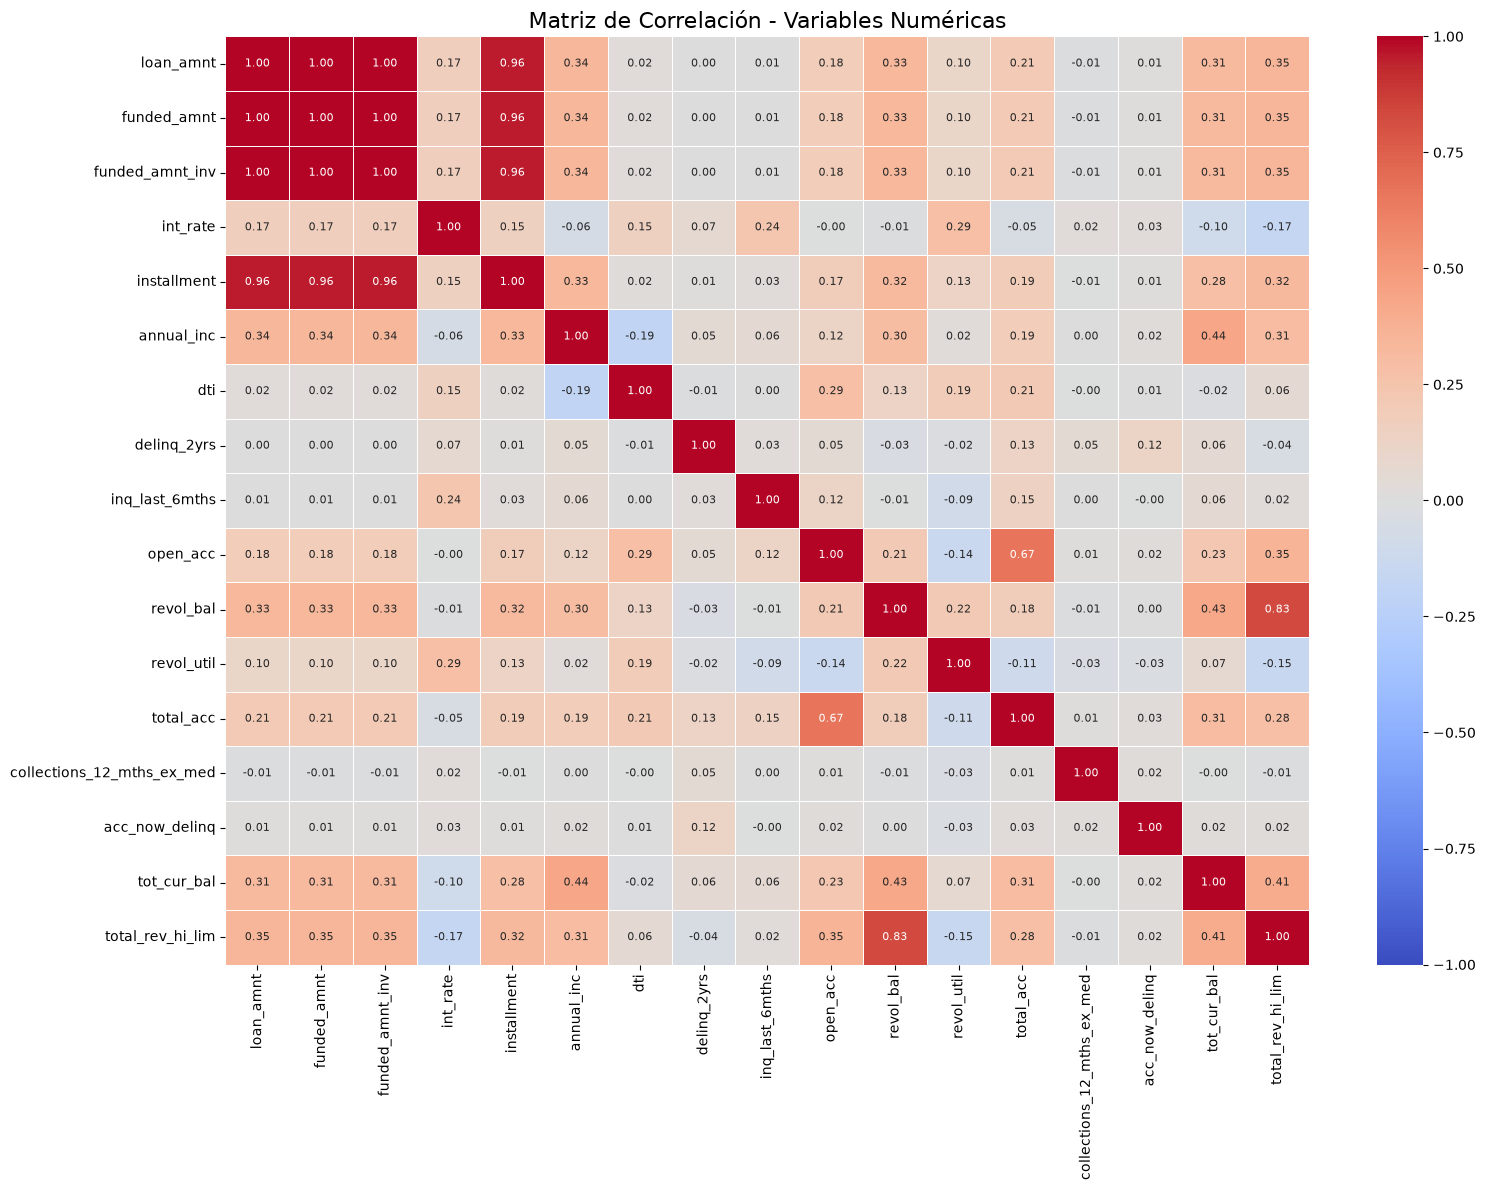

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calcula la matriz de correlación de Pearson
matriz_corr_num = numericas.corr()

# Configura y muestra el mapa de calor con los números
plt.figure(figsize=(16, 12))  # Figura un poco más grande para acomodar los números
sns.heatmap(matriz_corr_num, 
            annot=True,       # Muestra los valores numéricos
            fmt=".2f",        # Redondea a 2 decimales
            cmap='coolwarm', 
            vmin=-1, vmax=1, 
            linewidths=0.5,
            annot_kws={"size": 8})  # Tamaño de fuente más pequeño para los números
plt.title('Matriz de Correlación - Variables Numéricas', fontsize=16)
plt.tight_layout()
plt.show()

In [14]:
columnas_numericas_redundates = ["funded_amnt", "funded_amnt_inv", "installment", "total_rev_hi_lim"]

numericas = numericas.drop(columns=columnas_numericas_redundates)
df = df.drop(columns=columnas_numericas_redundates)

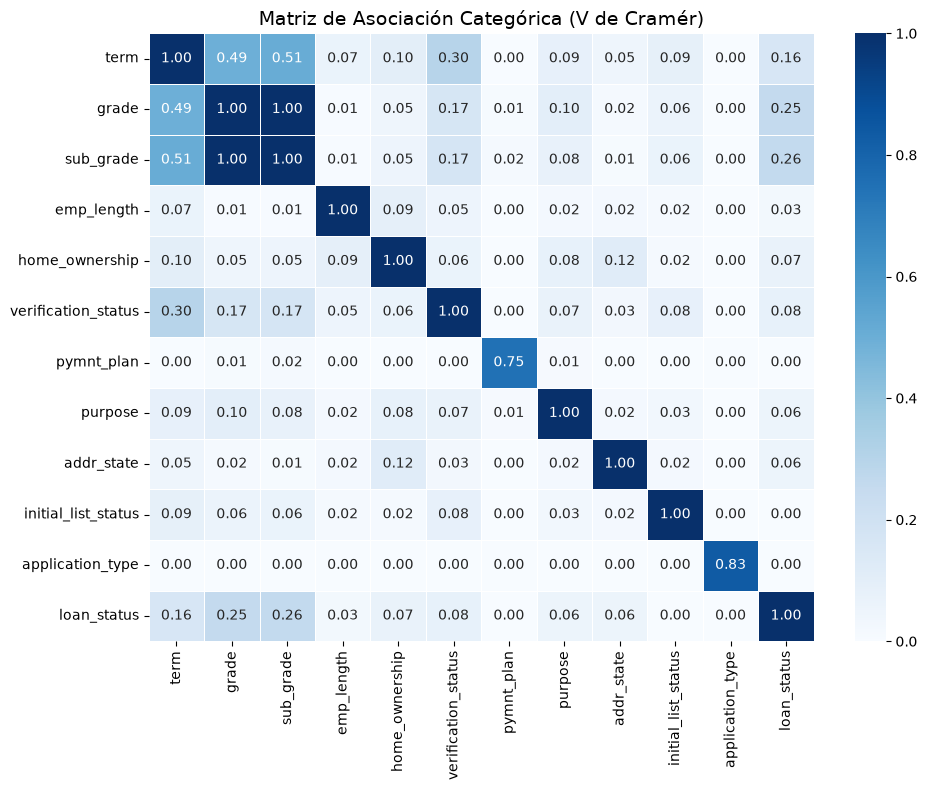

In [15]:
# %%
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

# Copiar las categóricas sin 'grade'
categoricas1 = categoricas.copy()

# AÑADIR LA VARIABLE OBJETIVO (Asegúrate de tomarla del dataframe que la contenga, por ejemplo 'df')
categoricas1['loan_status'] = df['loan_status']

# 1. Definir la función de V de Cramér
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    
    if n == 0 or r == 1 or k == 1:
        return 0.0
        
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# 2. Crear una matriz vacía 
columnas_cat = categoricas1.columns
matriz_cramer = pd.DataFrame(index=columnas_cat, columns=columnas_cat)

# 3. Calcular la V de Cramér para cada par de variables
for col1 in columnas_cat:
    for col2 in columnas_cat:
        matriz_cramer.loc[col1, col2] = cramers_v(categoricas1[col1], categoricas1[col2])

matriz_cramer = matriz_cramer.astype(float)

# 4. Visualizar en un Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(matriz_cramer, 
            annot=True,          
            cmap='Blues',        
            fmt=".2f", 
            vmin=0, vmax=1,
            linewidths=0.5)
plt.title('Matriz de Asociación Categórica (V de Cramér)', fontsize=14)
plt.tight_layout()
plt.show()

In [16]:
categoricas.columns

Index(['term', 'grade', 'sub_grade', 'emp_length', 'home_ownership',
       'verification_status', 'pymnt_plan', 'purpose', 'addr_state',
       'initial_list_status', 'application_type'],
      dtype='str')

In [17]:
columnas_categoricas_no_signifiativas = ["emp_length", "pymnt_plan", "initial_list_status", "application_type"]

columnas_categoricas_redundates = ["grade"]

categoricas = categoricas.drop(columns=columnas_categoricas_no_signifiativas+columnas_categoricas_redundates)
df = df.drop(columns=columnas_categoricas_no_signifiativas+columnas_categoricas_redundates)

## Codificación y exportación

La codificación (ordinal para `sub_grade` y `verification_status`, one-hot para el resto) y la exportación están en `src/preprocesamiento.py`, para que clasificación, regresión y la aplicación usen exactamente las mismas variables. Se regeneran con `python -m src.preprocesamiento`.

In [18]:
# La selección hecha arriba debe coincidir con la del módulo compartido
assert sorted(numericas.columns) == sorted(COLUMNAS_NUMERICAS)
assert sorted(categoricas.columns) == sorted(list(MAPEOS_ORDINALES) + COLUMNAS_ONE_HOT)
print("Selección de variables consistente con src/preprocesamiento.py")

Selección de variables consistente con src/preprocesamiento.py


In [19]:
df_final = generar_datos(df_og)
df_final.to_csv(RUTA_PROCESADOS, index=False)

print(f"{len(df_final):,} créditos | {len(columnas_entrada(df_final))} variables de entrada")
print(f"Archivo guardado correctamente en: {RUTA_PROCESADOS}")

193,050 créditos | 82 variables de entrada
Archivo guardado correctamente en: C:\Users\Usuario\Documents\GitHub\RedesNeuronales_Trabajo2\datasets\creditos_procesados.csv.gz


In [20]:
df_final.describe()

,id,issue_d,incumple,ead,lgd,loan_amnt,int_rate,annual_inc,dti,delinq_2yrs,...,addr_state_SD,addr_state_TN,addr_state_TX,addr_state_UT,addr_state_VA,addr_state_VT,addr_state_WA,addr_state_WI,addr_state_WV,addr_state_WY
count,1.930500e+05,193050,193050.000000,33110.000000,33110.000000,193050.000000,193050.000000,1.930500e+05,193050.000000,193050.000000,...,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000,193050.000000
mean,1.688285e+07,2014-01-07 17:34:28.699300,0.233023,12122.614298,0.931947,14413.481870,14.355545,7.479068e+04,17.417646,0.293074,...,0.002264,0.012934,0.078819,0.008853,0.031059,0.001611,0.023574,0.012411,0.004481,0.002388
min,5.716700e+04,2012-08-01 00:00:00,0.000000,2.190000,0.000000,1000.000000,5.320000,6.000000e+03,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,5.135362e+06,2013-05-01 00:00:00,0.000000,5993.387500,0.859005,8000.000000,11.140000,4.700000e+04,11.480000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,1.018349e+07,2014-01-01 00:00:00,0.000000,10569.025000,1.000000,12175.000000,14.090000,6.500000e+04,17.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,2.536709e+07,2014-09-01 00:00:00,0.000000,16762.237500,1.000000,20000.000000,17.270000,9.000000e+04,23.050000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,6.860466e+07,2015-12-01 00:00:00,1.000000,35000.000000,1.000000,35000.000000,28.990000,8.706582e+06,57.140000,29.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
std,1.572169e+07,NaN,0.422758,7638.466215,0.089648,8247.627782,4.455059,5.953106e+04,7.918548,0.816786,...,0.047524,0.112992,0.269457,0.093671,0.173478,0.040105,0.151719,0.110713,0.066788,0.048809


In [21]:
print("Todas las columnas numericas")

list(numericas.columns)

Todas las columnas numericas


['loan_amnt',
 'int_rate',
 'annual_inc',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_cur_bal']

In [22]:
print("Todas las columnas cualitativas, antres de ser tranformadas a label encoding y dummies")

list(categoricas.columns)

Todas las columnas cualitativas, antres de ser tranformadas a label encoding y dummies


['term',
 'sub_grade',
 'home_ownership',
 'verification_status',
 'purpose',
 'addr_state']

In [23]:
print("Columna de tiempo para evaluar")

list(df.select_dtypes("datetime"))

Columna de tiempo para evaluar


['issue_d']

In [24]:
print("Todas las columnas, incluida la objetivo: loan_status")
list(df.columns)

Todas las columnas, incluida la objetivo: loan_status


['loan_amnt',
 'term',
 'int_rate',
 'sub_grade',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'purpose',
 'addr_state',
 'dti',
 'delinq_2yrs',
 'inq_last_6mths',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'collections_12_mths_ex_med',
 'acc_now_delinq',
 'tot_cur_bal']